# MLOps Pipeline Testing & Model Evaluation

This notebook supports both single CSV and two-file (accel+gyro) input modes.
It auto-detects labels, applies configurable preprocessing, loads two models for comparison,
generates sliding windows, performs inference, and displays all metrics and visualizations inline.

## Configuration
Set input paths, preprocessing switches, memory controls, and model paths here. Unit conversion is only for accelerometer data when it is still in milliG.


In [ ]:
# ===== CONFIGURATION SECTION =====
# Adjust these settings before running.
#
# Important: the mentor/pretrained checkpoint currently scores better when the
# canonical scaler is skipped. That is a MODEL-CHECKPOINT debug finding, not a
# production-pipeline rule. Keep this toggle explicit so we do not accidentally
# double-scale or compare raw windows against scaled reference windows.

# Data Input: choose ONE mode
# Mode 1: single CSV with both accel and gyro columns
DATA_PATH = r'D:\study apply\ML Ops\MasterArbeit_MLops\notebooks\synthetic_labeled.csv'
# DATA_PATH = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\all_users_data_labeled.csv"

# Mode 2: separate accel and gyro files (two-file merge)
ACCEL_FILE = None
GYRO_FILE  = None

# Label column name (or None if no labels)
LABEL_COLUMN = 'activity'

# Preprocessing toggles
UNIT_CONVERSION        = False  # all_users_data_labeled.csv is already m/s^2; gyro remains deg/s
GRAVITY_REMOVAL        = False  # production/default training kept gravity included
DOMAIN_CALIBRATION     = False  # experimental/off
APPLY_CANONICAL_SCALER = False  # False currently gives the mentor checkpoint higher accuracy; True = production scaler path

# Two-file merge / resample
MERGE_TOLERANCE_MS = 1
TARGET_HZ          = 50

# Memory controls
WINDOW_DTYPE       = 'float32'
PREDICT_BATCH_SIZE = 32
MAX_WINDOWS        = None

# Model paths
PRETRAINED_MODEL_PATH = r"D:\study apply\ML Ops\MasterArbeit_MLops\models\pretrained\fine_tuned_model_1dcnnbilstm.keras"
TRAINED_MODEL_PATH    = None

# Project artifacts
PROJECT_ROOT_PATH     = r"D:\study apply\ML Ops\MasterArbeit_MLops"
CANONICAL_SCALER_PATH = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\prepared\scaler_train_only.json"
DRIFT_REFERENCE_PATH  = r"D:\study apply\ML Ops\MasterArbeit_MLops\models\drift_reference.json"
DRIFT_REFERENCE_DATA  = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\all_users_data_labeled.csv"
PIPELINE_CONFIG_PATH  = r"D:\study apply\ML Ops\MasterArbeit_MLops\config\pipeline_config.yaml"

# Mode-aware paired reference arrays for sanity checks.
REFERENCE_NPY_PATH_SCALED   = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\prepared\paired_windows\all_users_data_labeled_users_6_canonical_scaled_X.npy"
REFERENCE_NPY_LABELS_SCALED = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\prepared\paired_windows\all_users_data_labeled_users_6_canonical_scaled_y.npy"
REFERENCE_NPY_PATH_RAW      = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\prepared\paired_windows\all_users_data_labeled_users_6_raw_X.npy"
REFERENCE_NPY_LABELS_RAW    = r"D:\study apply\ML Ops\MasterArbeit_MLops\data\prepared\paired_windows\all_users_data_labeled_users_6_raw_y.npy"
REFERENCE_NPY_PATH   = REFERENCE_NPY_PATH_SCALED if APPLY_CANONICAL_SCALER else REFERENCE_NPY_PATH_RAW
REFERENCE_NPY_LABELS = REFERENCE_NPY_LABELS_SCALED if APPLY_CANONICAL_SCALER else REFERENCE_NPY_LABELS_RAW

# Window parameters
WINDOW_SIZE    = 200
WINDOW_OVERLAP = 0.5
WINDOW_STEP    = int(WINDOW_SIZE * (1 - WINDOW_OVERLAP))

# Activity class mapping - 11 classes matching src/utils/label_mapping.py
ACTIVITY_MAPPING = {
    'ear_rubbing':       0,
    'forehead_rubbing':  1,
    'hair_pulling':      2,
    'hand_scratching':   3,
    'hand_tapping':      4,
    'knuckles_cracking': 5,
    'nail_biting':       6,
    'nape_rubbing':      7,
    'sitting':           8,
    'smoking':           9,
    'standing':         10,
}

print('=== Configuration Loaded ===')
print(f'Single CSV       : {DATA_PATH}')
print(f'Accel / Gyro     : {ACCEL_FILE} / {GYRO_FILE}')
print(f'Preprocessing    : unit={UNIT_CONVERSION}, gravity={GRAVITY_REMOVAL}, calibrate={DOMAIN_CALIBRATION}, scaler={APPLY_CANONICAL_SCALER}')
print(f'Input mode       : {"canonical-scaled" if APPLY_CANONICAL_SCALER else "raw/debug for mentor checkpoint"}')
print(f'Reference .npy   : X={REFERENCE_NPY_PATH}')
print(f'Reference labels : y={REFERENCE_NPY_LABELS}')
print(f'Merge tolerance  : {MERGE_TOLERANCE_MS}ms  |  Target rate: {TARGET_HZ} Hz')
print(f'Predict batch    : {PREDICT_BATCH_SIZE}  |  Max windows: {MAX_WINDOWS}')
print(f'Pretrained       : {PRETRAINED_MODEL_PATH}')
print(f'Trained          : {TRAINED_MODEL_PATH}')|
print(f'Canonical scaler : {CANONICAL_SCALER_PATH}')
print(f'Drift reference  : {DRIFT_REFERENCE_PATH}')
print(f'Classes ({len(ACTIVITY_MAPPING)}): {list(ACTIVITY_MAPPING.keys())}')


SyntaxError: invalid syntax (94702366.py, line 85)

In [117]:
# ===== IMPORTS =====
import sys
from pathlib import Path

# Make src/ importable so we can use the production helpers directly.
_PROJECT_ROOT = Path(PROJECT_ROOT_PATH)
if str(_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_PROJECT_ROOT))

import pandas as pd
import numpy as np
import json
import warnings
from scipy.signal import butter, filtfilt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

# Production helpers
from src.utils.scaler import load_canonical_scaler, assert_scaler_integrity, CANONICAL_SCALER_PATH as _CANONICAL_SCALER_PATH
from src.components.data_ingestion import SENSOR_COLUMN_ALIASES, _build_alias_rename_map, _normalize_column_key
from src.monitoring.drift_monitor import DriftMonitor, CHANNELS as DRIFT_CHANNELS

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print('All imports successful')
print(f'  Production root on sys.path: {_PROJECT_ROOT}')
print(f'  Canonical scaler module path: {_CANONICAL_SCALER_PATH}')


All imports successful
  Production root on sys.path: D:\study apply\ML Ops\MasterArbeit_MLops
  Canonical scaler module path: D:\study apply\ML Ops\MasterArbeit_MLops\data\prepared\scaler_train_only.json


In [118]:
# Quick preview of raw file columns (informational only)
import pandas as pd
if ACCEL_FILE:
    _a = pd.read_csv(ACCEL_FILE, nrows=2)
    _g = pd.read_csv(GYRO_FILE,  nrows=2)
    print("Accel columns:", _a.columns.tolist())
    print("Gyro  columns:", _g.columns.tolist())
    del _a, _g
elif DATA_PATH:
    _d = pd.read_csv(DATA_PATH, nrows=2)
    print("Data columns:", _d.columns.tolist())
    del _d

Data columns: ['timestamp', 'Ax_w', 'Ay_w', 'Az_w', 'Gx_w', 'Gy_w', 'Gz_w', 'activity', 'User']


## Data Loading
Loads either one prepared CSV or separate accelerometer/gyroscope files. Numeric values are downcast after loading to reduce memory use.


In [119]:
# ===== STEP 1: DATA INGESTION (Single CSV or Two-File Merge) =====
# Mirrors src/components/data_ingestion.py: 1ms merge tolerance, 50 Hz resample,
# canonical column-alias normalization.

def optimize_dataframe_memory(df, exclude_cols=None):
    """Downcast numeric columns in-place to reduce notebook RAM use."""
    exclude_cols = set(exclude_cols or [])
    before_mb = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        if col in exclude_cols:
            continue
        if pd.api.types.is_float_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='float')
        elif pd.api.types.is_integer_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], downcast='integer')
    after_mb = df.memory_usage(deep=True).sum() / 1024**2
    print(f'Memory optimized: {before_mb:.1f} MB -> {after_mb:.1f} MB')
    return df


def _build_precise_time(df):
    base = pd.to_datetime(df['timestamp'])
    ms = pd.to_numeric(df['timestamp_ms'], errors='coerce')
    off = pd.to_numeric(df['sample_time_offset'], errors='coerce') if 'sample_time_offset' in df.columns else 0
    return base + pd.to_timedelta(ms + off, unit='ms')


def _resample_to_hz(df, target_hz=50, sensor_cols=None, label_col=None):
    """Resample a DataFrame indexed by 'timestamp' to a fixed rate.

    Sensor columns are linearly interpolated; label columns are forward/back-filled.
    """
    period_ms = int(round(1000.0 / target_hz))
    df = df.set_index('timestamp').sort_index()
    new_index = pd.date_range(df.index.min(), df.index.max(), freq=f'{period_ms}ms')
    df_re = df.reindex(df.index.union(new_index)).sort_index()
    if sensor_cols:
        df_re[sensor_cols] = df_re[sensor_cols].interpolate(method='time').astype(np.float32)
    if label_col and label_col in df_re.columns:
        df_re[label_col] = df_re[label_col].ffill().bfill()
    df_re = df_re.loc[new_index].reset_index().rename(columns={'index': 'timestamp'})
    return df_re


def load_data():
    if DATA_PATH:
        print(f'Loading single CSV: {DATA_PATH}')
        df = pd.read_csv(DATA_PATH, low_memory=False)
        df = optimize_dataframe_memory(df, exclude_cols=[LABEL_COLUMN] if LABEL_COLUMN else None)
        print(f'Loaded {len(df)} rows, columns: {df.columns.tolist()}')
        return df

    if ACCEL_FILE and GYRO_FILE:
        print(f'Loading accel: {ACCEL_FILE}')
        print(f'Loading gyro:  {GYRO_FILE}')

        accel_df = pd.read_csv(ACCEL_FILE, low_memory=False)
        gyro_df  = pd.read_csv(GYRO_FILE, low_memory=False)
        accel_df = optimize_dataframe_memory(accel_df)
        gyro_df  = optimize_dataframe_memory(gyro_df)

        accel_df['_t'] = _build_precise_time(accel_df)
        gyro_df['_t']  = _build_precise_time(gyro_df)

        accel_df = accel_df.sort_values('_t').reset_index(drop=True)
        gyro_df  = gyro_df.sort_values('_t').reset_index(drop=True)

        print(f"Accel time range: {accel_df['_t'].iloc[0]}  ->  {accel_df['_t'].iloc[-1]}")
        print(f"Gyro  time range: {gyro_df['_t'].iloc[0]}  ->  {gyro_df['_t'].iloc[-1]}")

        gyro_drop = [c for c in ['timestamp', 'timestamp_ms', 'sample_index', 'sample_time_offset']
                     if c in gyro_df.columns]
        gyro_slim = gyro_df.drop(columns=gyro_drop)

        # Production tolerance: 1ms (was 20ms in the unaligned notebook).
        df = pd.merge_asof(
            accel_df,
            gyro_slim,
            left_on='_t', right_on='_t',
            tolerance=pd.Timedelta(f'{MERGE_TOLERANCE_MS}ms'),
            direction='nearest',
        )

        gyro_sensor_cols = [c for c in df.columns if c.lower().startswith(('gyro_', 'g')) and c != 'timestamp']
        before = len(df)
        df = df.dropna(subset=gyro_sensor_cols).reset_index(drop=True)
        print(f'Rows before dropna: {before}  after: {len(df)}')

        df = df.rename(columns={'_t': 'timestamp'})
        df = df.drop(columns=[c for c in ['timestamp_ms', 'sample_index', 'sample_time_offset'] if c in df.columns])

        # Resample to the production rate.
        sensor_cols_for_resample = [c for c in df.columns
                                    if c not in ('timestamp', LABEL_COLUMN) and pd.api.types.is_float_dtype(df[c])]
        print(f'Resampling to {TARGET_HZ} Hz (linear interp on {len(sensor_cols_for_resample)} sensor cols)')
        df = _resample_to_hz(df, target_hz=TARGET_HZ,
                             sensor_cols=sensor_cols_for_resample,
                             label_col=LABEL_COLUMN if LABEL_COLUMN in df.columns else None)
        df = optimize_dataframe_memory(df, exclude_cols=['timestamp', LABEL_COLUMN] if LABEL_COLUMN else ['timestamp'])

        print(f'Final merged shape: {df.shape}')
        print(f'Columns: {df.columns.tolist()}')
        return df

    raise ValueError('Must set either DATA_PATH or both ACCEL_FILE and GYRO_FILE')

df_raw = load_data()

# --- Sampling-rate sanity check ---
# WINDOW_SIZE=200 was chosen for 50 Hz (4s windows). A 100 Hz CSV would
# pack 2s into 200 samples, which the model has never seen.
if 'timestamp' in df_raw.columns and len(df_raw) >= 2:
    try:
        _ts = pd.to_datetime(df_raw['timestamp'])
        _dt_ms = (_ts.diff().dt.total_seconds() * 1000).median()
        if _dt_ms and _dt_ms > 0:
            _hz = 1000.0 / _dt_ms
            print(f'Inferred sample rate: {_hz:.1f} Hz  '
                  f'(production expects {TARGET_HZ} Hz)')
            if abs(_hz - TARGET_HZ) > 5:
                print(f'  WARNING: input rate differs from {TARGET_HZ} Hz.')
                print(f'  Two-file mode auto-resamples; single-CSV mode does NOT.')
                print(f'  At {_hz:.0f} Hz, WINDOW_SIZE=200 covers '
                      f'{200/_hz:.2f}s, not {200/TARGET_HZ:.2f}s — model trained on {200/TARGET_HZ:.2f}s windows.')
        else:
            print('Could not infer sample rate from timestamp diffs.')
    except Exception as _e:
        print(f'Sample-rate check skipped: {_e}')
else:
    print('No timestamp column; sample-rate check skipped.')
print(f'\nRaw data shape: {df_raw.shape}')
print(df_raw.head())


Loading single CSV: D:\study apply\ML Ops\MasterArbeit_MLops\data\all_users_data_labeled.csv
Memory optimized: 75.2 MB -> 63.8 MB
Loaded 385326 rows, columns: ['timestamp', 'Ax_w', 'Ay_w', 'Az_w', 'Gx_w', 'Gy_w', 'Gz_w', 'activity', 'User']
Inferred sample rate: 50.0 Hz  (production expects 50 Hz)

Raw data shape: (385326, 9)
                 timestamp      Ax_w      Ay_w      Az_w       Gx_w      Gy_w  \
0  2005-05-01 00:04:59.000  8.500479 -4.885620 -1.247403 -18.151814  1.957602   
1  2005-05-01 00:04:59.020  8.628770 -4.715456 -1.247403 -20.759232  4.337617   
2  2005-05-01 00:04:59.040  8.571752 -4.521657 -0.966979 -18.816490  4.285163   
3  2005-05-01 00:04:59.060  8.581255 -4.436574 -0.962144 -16.541813  4.180101   
4  2005-05-01 00:04:59.080  8.310418 -4.394033 -0.957309 -22.858267  3.042800   

       Gz_w     activity  User  
0 -0.362040  ear_rubbing     1  
1 -1.517069  ear_rubbing     1  
2 -1.692155  ear_rubbing     1  
3 -1.744540  ear_rubbing     1  
4  0.792587  ear_rub

## Column and Label Detection
Detects accelerometer, gyroscope, and activity-label columns before preprocessing.


In [120]:
# ===== STEP 2: DATA VALIDATION & LABEL AUTO-DETECTION =====
# Uses the canonical SENSOR_COLUMN_ALIASES from src/components/data_ingestion.py
# so the notebook accepts every column variant the production ingest does.

def _resolve_to_canonical_sensor_cols(df):
    """Rename sensor columns to canonical [Ax, Ay, Az, Gx, Gy, Gz].

    Returns the renamed DataFrame plus the lists of accel and gyro column
    names IN that canonical order.
    """
    rename_map = _build_alias_rename_map(df.columns.tolist(), SENSOR_COLUMN_ALIASES)
    if rename_map:
        df = df.rename(columns=rename_map)
    canonical = ['Ax', 'Ay', 'Az', 'Gx', 'Gy', 'Gz']
    missing = [c for c in canonical if c not in df.columns]
    if missing:
        raise ValueError(
            f'Could not resolve sensor columns to canonical names. Missing: {missing}\n'
            f'Available columns: {df.columns.tolist()}'
        )
    return df, canonical[:3], canonical[3:], rename_map


def detect_labels(df):
    if LABEL_COLUMN and LABEL_COLUMN in df.columns:
        return LABEL_COLUMN
    for col in ['activity', 'label', 'activity_type', 'action']:
        if col in df.columns:
            return col
    return None


df_raw, accel_cols, gyro_cols, _rename_map = _resolve_to_canonical_sensor_cols(df_raw)
label_col = detect_labels(df_raw)

print(f'Sensor column rename map: {_rename_map if _rename_map else "(already canonical)"}')
print(f'Accel columns (canonical): {accel_cols}')
print(f'Gyro  columns (canonical): {gyro_cols}')
print(f'Label column             : {label_col}')
print(f'Has labels               : {label_col is not None}')

if label_col:
    print(f'Unique labels: {df_raw[label_col].unique()}')
    print(f'Label value counts:\n{df_raw[label_col].value_counts()}')

print(f'\nMissing values per column:')
print(df_raw.isnull().sum())


Sensor column rename map: {'Ax_w': 'Ax', 'Ay_w': 'Ay', 'Az_w': 'Az', 'Gx_w': 'Gx', 'Gy_w': 'Gy', 'Gz_w': 'Gz'}
Accel columns (canonical): ['Ax', 'Ay', 'Az']
Gyro  columns (canonical): ['Gx', 'Gy', 'Gz']
Label column             : activity
Has labels               : True
Unique labels: ['ear_rubbing' 'forehead_rubbing' 'hair_pulling' 'hand_scratching'
 'hand_tapping' 'knuckles_cracking' 'nail_biting' 'nape_rubbing' 'smoking'
 'sitting' 'standing']
Label value counts:
activity
nail_biting          38924
smoking              36093
hair_pulling         35461
forehead_rubbing     35219
hand_scratching      34975
sitting              34949
knuckles_cracking    34863
ear_rubbing          34768
standing             33859
hand_tapping         33366
nape_rubbing         32849
Name: count, dtype: int64

Missing values per column:
timestamp    0
Ax           0
Ay           0
Az           0
Gx           0
Gy           0
Gz           0
activity     0
User         0
dtype: int64


## Unit Check and Preprocessing
Checks whether acceleration looks like milliG or m/s^2. Conversion is applied only to accelerometer columns; gyroscope stays in degrees/second.


In [121]:
# ===== STEP 3: DATA PREPROCESSING =====
# Mirrors src/preprocess_data.py:
#   1. Unit conversion (milliG -> m/s^2) for accel only
#   2. Gravity removal: Butterworth high-pass, 0.3 Hz, order 3, filtfilt (accel only)
#   3. Domain calibration: shift to training mean (optional)
#   4. Scaling: load canonical train-only scaler; never fit on current data

# Production training-mean used by DomainCalibrator (RAW m/s^2 / deg-s, pre-scaling).
PRODUCTION_TRAINING_MEAN = np.array(
    [3.22, 1.28, -3.53, 0.60, 0.23, 0.09], dtype=np.float64
)

GRAVITY_FILTER_CUTOFF_HZ = 0.3
GRAVITY_FILTER_ORDER     = 3
GRAVITY_FILTER_FS        = float(TARGET_HZ)


def infer_accel_unit_need(df, accel_cols):
    accel = df[accel_cols].apply(pd.to_numeric, errors='coerce').dropna()
    if accel.empty:
        return {'decision': 'unknown', 'median_norm': np.nan, 'message': 'No valid accelerometer rows.'}

    sample = accel.sample(min(len(accel), 50_000), random_state=42) if len(accel) > 50_000 else accel
    norms = np.linalg.norm(sample.to_numpy(dtype=np.float32, copy=False), axis=1)
    median_norm = float(np.nanmedian(norms))

    if median_norm > 100:
        return {'decision': 'convert', 'median_norm': median_norm,
                'message': 'Acceleration looks like milliG; enable UNIT_CONVERSION=True.'}
    if 3 <= median_norm <= 30:
        return {'decision': 'do_not_convert', 'median_norm': median_norm,
                'message': 'Acceleration looks like m/s^2; keep UNIT_CONVERSION=False.'}
    return {'decision': 'ambiguous', 'median_norm': median_norm,
            'message': 'Scale is ambiguous; verify units from the data logger/export.'}


def remove_gravity_butter(df, accel_cols, cutoff_hz, fs, order):
    """Production-equivalent gravity removal via Butterworth high-pass + filtfilt."""
    nyquist = fs / 2.0
    normalized_cutoff = cutoff_hz / nyquist
    b, a = butter(order, normalized_cutoff, btype='high', output='ba')
    df_out = df.copy()
    for col in accel_cols:
        values = df[col].values.astype(np.float64)
        valid_mask = ~np.isnan(values)
        if valid_mask.sum() <= order * 3:
            print(f'  {col}: too few valid samples for Butterworth filter, leaving as-is')
            continue
        # Interpolate NaNs only for the duration of the filter pass.
        interp = np.interp(np.arange(len(values)), np.where(valid_mask)[0], values[valid_mask])
        filtered = filtfilt(b, a, interp)
        df_out[col] = filtered.astype(np.float32)
    return df_out


def preprocess_data(df, accel_cols, gyro_cols):
    df = df.copy()
    all_sensor_cols = accel_cols + gyro_cols
    df[all_sensor_cols] = df[all_sensor_cols].apply(pd.to_numeric, errors='coerce').astype(np.float32)

    unit_report = infer_accel_unit_need(df, accel_cols)
    print(f"[unit-check] median |a|={unit_report['median_norm']:.3f}  -> {unit_report['message']}")

    gyro_before = df[gyro_cols].copy(deep=True)

    # Step 1: Unit conversion (accel only).
    if UNIT_CONVERSION:
        print('[step 1] Converting accelerometer milliG -> m/s^2 (gyro untouched).')
        df.loc[:, accel_cols] = df[accel_cols] * np.float32(0.00981)

    if not np.allclose(gyro_before.to_numpy(), df[gyro_cols].to_numpy(), equal_nan=True):
        raise AssertionError('Gyroscope values changed during unit conversion.')

    # Step 2: Gravity removal (Butterworth high-pass, accel only).
    if GRAVITY_REMOVAL:
        print(f'[step 2] Gravity removal: Butterworth high-pass '
              f'(cutoff={GRAVITY_FILTER_CUTOFF_HZ}Hz, order={GRAVITY_FILTER_ORDER}, fs={GRAVITY_FILTER_FS}Hz).')
        for col in accel_cols:
            print(f'  before {col}: mean={df[col].mean():.3f} m/s^2')
        df = remove_gravity_butter(df, accel_cols,
                                   cutoff_hz=GRAVITY_FILTER_CUTOFF_HZ,
                                   fs=GRAVITY_FILTER_FS,
                                   order=GRAVITY_FILTER_ORDER)
        for col in accel_cols:
            print(f'  after  {col}: mean={df[col].mean():.3f} m/s^2')
    else:
        print('[step 2] Gravity removal: DISABLED')

    # Step 3: Domain calibration (optional).
    if DOMAIN_CALIBRATION:
        print('[step 3] Domain calibration: shifting to production training mean.')
        cur_mean = df[all_sensor_cols].mean().to_numpy(dtype=np.float64)
        shift = PRODUCTION_TRAINING_MEAN - cur_mean
        for i, col in enumerate(all_sensor_cols):
            df[col] = (df[col].astype(np.float64) + shift[i]).astype(np.float32)
        print(f'  applied shift: {np.round(shift, 3)}')
    else:
        print('[step 3] Domain calibration: DISABLED')

    # Step 4: Scaling via the canonical train-only scaler (NEVER fit here).
    if APPLY_CANONICAL_SCALER:
        print('[step 4] Loading canonical scaler (production train-only fit).')
        assert_scaler_integrity(CANONICAL_SCALER_PATH)
        canonical_mean, canonical_scale, canonical_cfg = load_canonical_scaler()
        expected_cols = canonical_cfg['sensor_cols']  # ['Ax','Ay','Az','Gx','Gy','Gz']
        if all_sensor_cols != expected_cols:
            raise AssertionError(
                f'Sensor column order {all_sensor_cols} does not match scaler order {expected_cols}'
            )
        safe_scale = np.where(canonical_scale == 0, 1.0, canonical_scale)
        print(f'  scaler mean : {np.round(canonical_mean, 3).tolist()}')
        print(f'  scaler scale: {np.round(canonical_scale, 3).tolist()}')
        df.loc[:, all_sensor_cols] = (
            (df[all_sensor_cols].to_numpy(dtype=np.float32) - canonical_mean) / safe_scale
        ).astype(np.float32)
    else:
        print('[step 4] Canonical scaler: DISABLED (APPLY_CANONICAL_SCALER=False).')
        print('         Feeding raw values to the model. Use this only as a debug A/B.')

    return optimize_dataframe_memory(df, exclude_cols=[label_col] if label_col else None)


df_processed = preprocess_data(df_raw, accel_cols, gyro_cols)
print(f'\nProcessed data shape: {df_processed.shape}')
show_cols = accel_cols[0:3] + gyro_cols[0:3]
print(df_processed[show_cols].head())


[unit-check] median |a|=9.777  -> Acceleration looks like m/s^2; keep UNIT_CONVERSION=False.
[step 2] Gravity removal: DISABLED
[step 3] Domain calibration: DISABLED
[step 4] Canonical scaler: DISABLED (APPLY_CANONICAL_SCALER=False).
         Feeding raw values to the model. Use this only as a debug A/B.
Memory optimized: 63.8 MB -> 63.8 MB

Processed data shape: (385326, 9)
         Ax        Ay        Az         Gx        Gy        Gz
0  8.500479 -4.885620 -1.247403 -18.151814  1.957602 -0.362040
1  8.628770 -4.715456 -1.247403 -20.759232  4.337617 -1.517069
2  8.571752 -4.521657 -0.966979 -18.816490  4.285163 -1.692155
3  8.581255 -4.436574 -0.962144 -16.541813  4.180101 -1.744540
4  8.310418 -4.394033 -0.957309 -22.858267  3.042800  0.792587


## Window Generation
Builds model windows with a float32 strided view to avoid copying every overlapping window into RAM.


In [122]:
# ===== STEP 4: SLIDING WINDOW GENERATION =====

def create_windows(df, accel_cols, gyro_cols, window_size=200, step=100, label_col=None, max_windows=None):
    """
    Generate sliding windows without building a large Python list.

    The sensor matrix is float32 and windows are created as a NumPy strided view.
    This avoids the main RAM spike from list-of-arrays -> float64 ndarray conversion.
    """
    all_sensor_cols = accel_cols + gyro_cols
    sensor_values = np.ascontiguousarray(df[all_sensor_cols].to_numpy(dtype=np.float32, copy=False))

    if len(sensor_values) < window_size:
        empty = np.empty((0, window_size, len(all_sensor_cols)), dtype=np.float32)
        return empty, None if label_col is None else np.array([]), np.array([], dtype=np.int64)

    all_windows = np.lib.stride_tricks.sliding_window_view(
        sensor_values,
        window_shape=(window_size, len(all_sensor_cols))
    )[:, 0, :, :]
    windows = all_windows[::step]

    if max_windows is not None:
        windows = windows[:max_windows]

    indices = np.arange(0, len(windows) * step, step, dtype=np.int64)

    labels = None
    if label_col is not None:
        label_values = df[label_col].to_numpy()
        labels = []
        for i in indices:
            window_labels = pd.Series(label_values[i:i + window_size])
            most_common = window_labels.mode(dropna=True)
            labels.append(most_common.iloc[0] if len(most_common) > 0 else window_labels.iloc[0])
        labels = np.asarray(labels)

    return windows, labels, indices

X, y, indices = create_windows(
    df_processed,
    accel_cols,
    gyro_cols,
    window_size=WINDOW_SIZE,
    step=WINDOW_STEP,
    label_col=label_col,
    max_windows=MAX_WINDOWS
)

print(f'Windows shape: {X.shape}')  # (n_windows, 200, 6)
print(f'Windows dtype: {X.dtype}; view-backed: {X.base is not None}')
print(f'Approx window storage if copied: {X.nbytes / 1024**2:.1f} MB')
print(f'Label shape: {y.shape if y is not None else "None"}')
print(f'Window indices shape: {indices.shape}')

if y is not None:
    print(f'\nLabel distribution in windows:')
    unique, counts = np.unique(y, return_counts=True)
    for u, c in zip(unique, counts):
        print(f'  {u}: {c}')


Windows shape: (3852, 200, 6)
Windows dtype: float32; view-backed: True
Approx window storage if copied: 17.6 MB
Label shape: (3852,)
Window indices shape: (3852,)

Label distribution in windows:
  ear_rubbing: 347
  forehead_rubbing: 353
  hair_pulling: 355
  hand_scratching: 349
  hand_tapping: 333
  knuckles_cracking: 349
  nail_biting: 390
  nape_rubbing: 327
  sitting: 351
  smoking: 361
  standing: 337


## Model Loading
Loads the configured Keras model files.


In [123]:
# ===== STEP 5: MODEL LOADING =====

def load_model(model_path):
    """
    Load a TensorFlow/Keras model from .h5 file.
    """
    if not model_path:
        return None
    
    print(f'Loading model: {model_path}')
    model = tf.keras.models.load_model(model_path)
    print(f'Model loaded successfully. Input shape: {model.input_shape}, Output shape: {model.output_shape}')
    return model

pretrained_model = load_model(PRETRAINED_MODEL_PATH)
trained_model = load_model(TRAINED_MODEL_PATH)

if not pretrained_model and not trained_model:
    raise ValueError('At least one model path must be set')

print('\nModels loaded successfully')

Loading model: D:\study apply\ML Ops\MasterArbeit_MLops\models\pretrained\fine_tuned_model_1dcnnbilstm.keras
Model loaded successfully. Input shape: (None, 200, 6), Output shape: (None, 11)

Models loaded successfully


In [124]:
# ===== STEP 5b: REFERENCE-ARRAY SANITY CHECK =====
# Runs the loaded model on a pre-windowed reference array (.npy) WITHOUT
# any preprocessing. Use this to isolate whether the model itself is fine,
# and to read off which input space the model expects.
#
# REFERENCE_NPY_PATH / REFERENCE_NPY_LABELS default to the production
# training array, but you can repoint them at any pre-windowed file
# (e.g. an .npy you exported from this notebook for the current DATA_PATH).

if REFERENCE_NPY_PATH and Path(REFERENCE_NPY_PATH).exists():
    print(f'Loading reference array: {REFERENCE_NPY_PATH}')
    X_ref = np.load(REFERENCE_NPY_PATH)
    y_ref = np.load(REFERENCE_NPY_LABELS) if REFERENCE_NPY_LABELS and Path(REFERENCE_NPY_LABELS).exists() else None

    print(f'  X_ref shape: {X_ref.shape}')
    if y_ref is not None:
        print(f'  y_ref shape: {y_ref.shape}')
    flat_ref = X_ref.reshape(-1, X_ref.shape[-1])
    print(f'  Per-channel mean: {np.round(flat_ref.mean(0), 3).tolist()}')
    print(f'  Per-channel std : {np.round(flat_ref.std(0), 3).tolist()}')
    print(f'  Per-channel min : {np.round(flat_ref.min(0), 3).tolist()}')
    print(f'  Per-channel max : {np.round(flat_ref.max(0), 3).tolist()}')

    # Heuristic verdict on which space this array lives in.
    means_abs_max = float(np.abs(flat_ref.mean(0)).max())
    std_avg = float(flat_ref.std(0).mean())
    if means_abs_max < 0.5 and 0.5 < std_avg < 1.5:
        ref_space = 'SCALED (mean ~0, std ~1)'
    elif std_avg > 5:
        ref_space = 'RAW (large per-channel std)'
    else:
        ref_space = 'AMBIGUOUS'
    print(f'  Verdict: reference array looks {ref_space}')

    # Use whichever model is loaded (pretrained takes precedence).
    sanity_model = pretrained_model if pretrained_model is not None else trained_model
    if sanity_model is None:
        print('  No model loaded; skipping accuracy check.')
    else:
        n = min(5000, len(X_ref))
        probs_ref = sanity_model.predict(X_ref[:n], batch_size=PREDICT_BATCH_SIZE, verbose=0)
        preds_ref = probs_ref.argmax(axis=1)
        mean_conf_ref = float(probs_ref.max(axis=1).mean())
        print(f'\n  Sanity prediction on first {n} windows (NO preprocessing):')
        print(f'    Mean top-1 confidence: {mean_conf_ref:.4f}')
        if y_ref is not None:
            acc_ref = float((preds_ref == y_ref[:n]).mean())
            print(f'    Accuracy vs reference labels: {acc_ref:.4f}')
            if acc_ref > 0.7:
                print('    -> Model looks healthy on this reference array.')
                print(f'       Feed live data in the same space as the reference '
                      f'(see verdict above).')
            elif acc_ref < 0.3:
                print('    -> Even on the reference array the model is failing.')
                print('       Either the model file is wrong, or the class index ordering')
                print('       differs from ACTIVITY_MAPPING. Inspect both before tuning preprocessing.')
            else:
                print('    -> Mid-range accuracy on the reference array — inspect class')
                print('       index ordering vs ACTIVITY_MAPPING.')
        else:
            print('    (No labels file provided; cannot compute accuracy.)')
else:
    print(f'REFERENCE_NPY_PATH not set or missing ({REFERENCE_NPY_PATH}); skipping sanity check.')


NameError: name 'REFERENCE_NPY_PATH' is not defined

## Inference and Confidence Analysis
Runs batched prediction and summarizes confidence, entropy, margin, and class-level uncertainty.



=== Input space report: X (post-preprocessing windows) ===
  Shape        : (3852, 200, 6)
  Mean per ch  : [3.2200000286102295, 1.281999945640564, -3.5299999713897705, 0.6010000109672546, 0.22499999403953552, 0.08900000154972076]
  Std  per ch  : [6.566999912261963, 4.35099983215332, 3.2360000610351562, 49.9010009765625, 14.805000305175781, 14.16100025177002]
  Min  per ch  : [-26.84600067138672, -16.56100082397461, -45.22999954223633, -818.9520263671875, -302.4219970703125, -242.4080047607422]
  Max  per ch  : [31.95400047302246, 41.858001708984375, 24.149999618530273, 835.1719970703125, 206.93299865722656, 231.8350067138672]
  Verdict      : input arr looks RAW (large per-channel std, gyro often >10)

=== PRETRAINED MODEL ===
Running inference on 3852 windows...

  Pretrained Model  —  Confidence & Uncertainty
  Windows              : 3852
  Confidence mean±std  : 0.7666 ± 0.1685
  Confidence min/max   : 0.3033 / 1.0000
  Low-conf (<0.50)     : 7.17%  (276 windows)
  Entropy  mean±

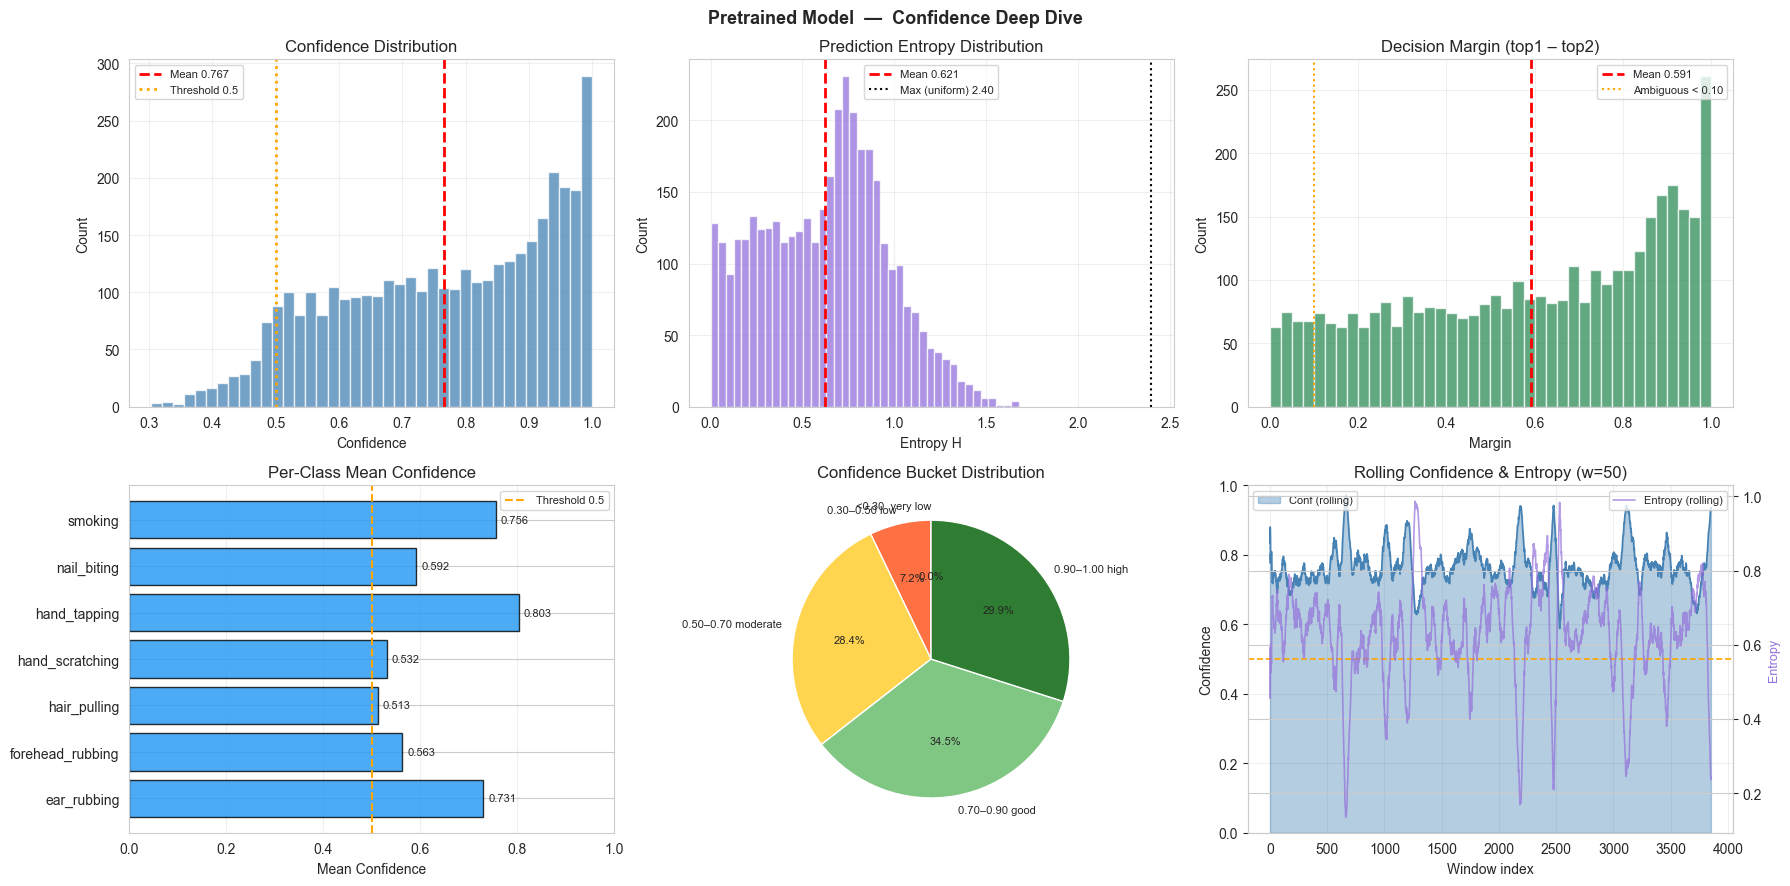

In [125]:
# ===== STEP 6: INFERENCE & DEEP CONFIDENCE ANALYSIS =====
#
# Confidence score = max softmax probability (top-1).
#   > 0.80          → high confidence, model is decisive
#   0.50 – 0.80     → moderate, treat with caution
#   < 0.50          → low confidence (random baseline for 11 classes = 0.09)
#
# Metrics computed:
#   mean/std/min/max confidence
#   low_conf_rate       — % windows below threshold
#   entropy             — H = -sum(p*log(p)); 0=certain, 2.40=uniform random
#   margin              — top1 prob – top2 prob; small = ambiguous
#   per-class confidence — which activity is predicted most/least confidently
#   confidence buckets  — 5 bands: [0–0.3, 0.3–0.5, 0.5–0.7, 0.7–0.9, 0.9–1.0]
#   rolling confidence  — temporal heatmap, shows if model degrades mid-recording

CONFIDENCE_THRESHOLD = 0.5

def run_inference(model, X, activity_mapping):
    if len(X) == 0:
        print("Warning: No windows to run inference on.")
        return None
    print(f'Running inference on {len(X)} windows...')
    probs = model.predict(X, batch_size=PREDICT_BATCH_SIZE, verbose=0).astype(np.float32, copy=False)

    confidences    = np.max(probs, axis=1)
    pred_class_idx = np.argmax(probs, axis=1)
    idx_to_act     = {v: k for k, v in activity_mapping.items()}
    pred_activities = np.array([idx_to_act.get(i, f'class_{i}') for i in pred_class_idx])

    eps     = 1e-9
    entropy = -np.sum(probs * np.log(probs + eps), axis=1)
    sp      = np.sort(probs, axis=1)[:, ::-1]
    margin  = sp[:, 0] - sp[:, 1]

    top5_idx   = np.argsort(probs, axis=1)[:, -5:][:, ::-1]
    top5_probs = np.take_along_axis(probs, top5_idx, axis=1)
    top5_names = np.vectorize(idx_to_act.get)(top5_idx)

    return dict(confidences=confidences, pred_class_idx=pred_class_idx,
                pred_activities=pred_activities, probs=probs,
                entropy=entropy, margin=margin,
                top5_idx=top5_idx, top5_probs=top5_probs, top5_names=top5_names)


def deep_confidence_analysis(results, model_name):
    c   = results['confidences']
    ent = results['entropy']
    mar = results['margin']
    acts = results['pred_activities']
    n   = len(c)
    low = (c < CONFIDENCE_THRESHOLD).mean()
    max_ent = -np.log(1 / len(ACTIVITY_MAPPING))

    # ── printed summary ──────────────────────────────────────────────────────
    print(f'\n{"="*65}')
    print(f'  {model_name}  —  Confidence & Uncertainty')
    print(f'{"="*65}')
    print(f'  Windows              : {n}')
    print(f'  Confidence mean±std  : {c.mean():.4f} ± {c.std():.4f}')
    print(f'  Confidence min/max   : {c.min():.4f} / {c.max():.4f}')
    print(f'  Low-conf (<{CONFIDENCE_THRESHOLD:.2f})     : {low:.2%}  ({int(low*n)} windows)')
    print(f'  Entropy  mean±std    : {ent.mean():.4f} ± {ent.std():.4f}  (max={max_ent:.2f})')
    print(f'  Margin   mean±std    : {mar.mean():.4f} ± {mar.std():.4f}')
    print(f'  Ambiguous (mar<0.10) : {(mar < 0.10).mean():.2%}')

    # per-class confidence
    print(f'\n  Per-class mean confidence:')
    for act in sorted(set(acts)):
        mask = acts == act
        mc = c[mask].mean() if mask.sum() > 0 else 0.0
        bar = '█' * int(mc * 20)
        print(f'    {act:<22} {mc:.3f}  {bar}')

    # confidence buckets
    buckets = [(0.0,0.3,'<0.30  very low'),
               (0.3,0.5,'0.30–0.50 low'),
               (0.5,0.7,'0.50–0.70 moderate'),
               (0.7,0.9,'0.70–0.90 good'),
               (0.9,1.0,'0.90–1.00 high')]
    print(f'\n  Confidence bucket distribution:')
    for lo, hi, label in buckets:
        cnt = ((c >= lo) & (c < hi)).sum()
        pct = cnt / n
        bar = '█' * int(pct * 40)
        print(f'    {label:<22} {cnt:>5} ({pct:>5.1%})  {bar}')

    # ── plots ─────────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    fig.suptitle(f'{model_name}  —  Confidence Deep Dive', fontsize=13, fontweight='bold')

    # 1. Confidence histogram
    ax = axes[0, 0]
    ax.hist(c, bins=40, color='steelblue', alpha=0.75, edgecolor='white')
    ax.axvline(c.mean(), color='red',    linestyle='--', lw=2, label=f'Mean {c.mean():.3f}')
    ax.axvline(CONFIDENCE_THRESHOLD, color='orange', linestyle=':', lw=2,
               label=f'Threshold {CONFIDENCE_THRESHOLD}')
    ax.set_title('Confidence Distribution')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Count')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

    # 2. Entropy histogram
    ax = axes[0, 1]
    ax.hist(ent, bins=40, color='mediumpurple', alpha=0.75, edgecolor='white')
    ax.axvline(ent.mean(), color='red', linestyle='--', lw=2, label=f'Mean {ent.mean():.3f}')
    ax.axvline(max_ent,    color='black', linestyle=':', lw=1.5, label=f'Max (uniform) {max_ent:.2f}')
    ax.set_title('Prediction Entropy Distribution')
    ax.set_xlabel('Entropy H'); ax.set_ylabel('Count')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

    # 3. Margin histogram
    ax = axes[0, 2]
    ax.hist(mar, bins=40, color='seagreen', alpha=0.75, edgecolor='white')
    ax.axvline(mar.mean(), color='red', linestyle='--', lw=2, label=f'Mean {mar.mean():.3f}')
    ax.axvline(0.10, color='orange', linestyle=':', lw=1.5, label='Ambiguous < 0.10')
    ax.set_title('Decision Margin (top1 – top2)')
    ax.set_xlabel('Margin'); ax.set_ylabel('Count')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

    # 4. Per-class mean confidence bar
    ax = axes[1, 0]
    act_labels = sorted(set(acts))
    per_class_conf = [c[acts == a].mean() if (acts == a).sum() > 0 else 0 for a in act_labels]
    colors_pc = ['#2196F3' if v >= CONFIDENCE_THRESHOLD else '#FF5722' for v in per_class_conf]
    bars = ax.barh(act_labels, per_class_conf, color=colors_pc, alpha=0.8, edgecolor='black')
    ax.axvline(CONFIDENCE_THRESHOLD, color='orange', linestyle='--', lw=1.5,
               label=f'Threshold {CONFIDENCE_THRESHOLD}')
    ax.set_xlim(0, 1); ax.set_title('Per-Class Mean Confidence')
    ax.set_xlabel('Mean Confidence'); ax.legend(fontsize=8); ax.grid(axis='x', alpha=0.3)
    for bar, val in zip(bars, per_class_conf):
        ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=8)

    # 5. Confidence buckets pie
    ax = axes[1, 1]
    bucket_counts = [((c >= lo) & (c < hi)).sum() for lo, hi, _ in buckets]
    bucket_labels = [lbl for _, _, lbl in buckets]
    bucket_colors = ['#d32f2f','#ff7043','#ffd54f','#81c784','#2e7d32']
    wedges, texts, autotexts = ax.pie(
        bucket_counts, labels=bucket_labels, colors=bucket_colors,
        autopct='%1.1f%%', startangle=90, textprops={'fontsize': 8})
    ax.set_title('Confidence Bucket Distribution')

    # 6. Rolling confidence over time (window=50)
    ax = axes[1, 2]
    roll_w = 50
    rolling_conf = pd.Series(c).rolling(roll_w, min_periods=1).mean().values
    rolling_ent  = pd.Series(ent).rolling(roll_w, min_periods=1).mean().values
    ax.fill_between(range(n), rolling_conf, alpha=0.4, color='steelblue', label='Conf (rolling)')
    ax.plot(range(n), rolling_conf, color='steelblue', lw=1.2)
    ax2 = ax.twinx()
    ax2.plot(range(n), rolling_ent, color='mediumpurple', lw=1.2, alpha=0.7, label='Entropy (rolling)')
    ax2.set_ylabel('Entropy', color='mediumpurple', fontsize=9)
    ax.axhline(CONFIDENCE_THRESHOLD, color='orange', linestyle='--', lw=1.2)
    ax.set_ylim(0, 1); ax.set_title(f'Rolling Confidence & Entropy (w={roll_w})')
    ax.set_xlabel('Window index'); ax.set_ylabel('Confidence')
    ax.legend(loc='upper left', fontsize=8)
    ax2.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


def report_input_space(arr, label='windows'):
    """Print per-channel stats so we can tell which space `arr` lives in.

    Compared against the canonical scaler stats:
      training raw  mean = [2.34, 0.59, -3.59, 0.67, 0.25, 0.06]
      training raw  std  = [6.89, 4.67,  3.08, 54.79, 15.50, 14.53]
      training scaled    -> mean ~0, std ~1
    """
    flat = arr.reshape(-1, arr.shape[-1])
    mu, sd = flat.mean(axis=0), flat.std(axis=0)
    print(f'\n=== Input space report: {label} ===')
    print(f'  Shape        : {arr.shape}')
    print(f'  Mean per ch  : {np.round(mu, 3).tolist()}')
    print(f'  Std  per ch  : {np.round(sd, 3).tolist()}')
    print(f'  Min  per ch  : {np.round(flat.min(0), 3).tolist()}')
    print(f'  Max  per ch  : {np.round(flat.max(0), 3).tolist()}')
    means_abs_max = float(np.abs(mu).max())
    std_avg = float(sd.mean())
    if means_abs_max < 0.5 and 0.5 < std_avg < 1.5:
        verdict = 'SCALED (mean ~0, std ~1)'
    elif std_avg > 5:
        verdict = 'RAW (large per-channel std, gyro often >10)'
    else:
        verdict = 'AMBIGUOUS - inspect manually'
    print(f'  Verdict      : input arr looks {verdict}')

report_input_space(X, label='X (post-preprocessing windows)')

# Run inference
results_pretrained = None
results_trained    = None

if pretrained_model:
    print('\n=== PRETRAINED MODEL ===')
    results_pretrained = run_inference(pretrained_model, X, ACTIVITY_MAPPING)
    if results_pretrained:
        deep_confidence_analysis(results_pretrained, 'Pretrained Model')

if trained_model:
    print('\n=== TRAINED MODEL ===')
    results_trained = run_inference(trained_model, X, ACTIVITY_MAPPING)
    if results_trained:
        deep_confidence_analysis(results_trained, 'Trained Model')


  Pretrained Model — Flip Rate Analysis
  Total windows          : 3852
  Consecutive pairs      : 3851
  Flip rate              : 38.46%  (1481 flips)
  Mean run length        : 2.6 windows  (stable streak)
  Max run length         : 66 windows
  Flips after low-conf   : 163 / 1481  (11%)
  Flips after high-conf  : 1318 / 1481  (89%)

  Verdict: Unstable — frequent class changes, model may be uncertain.


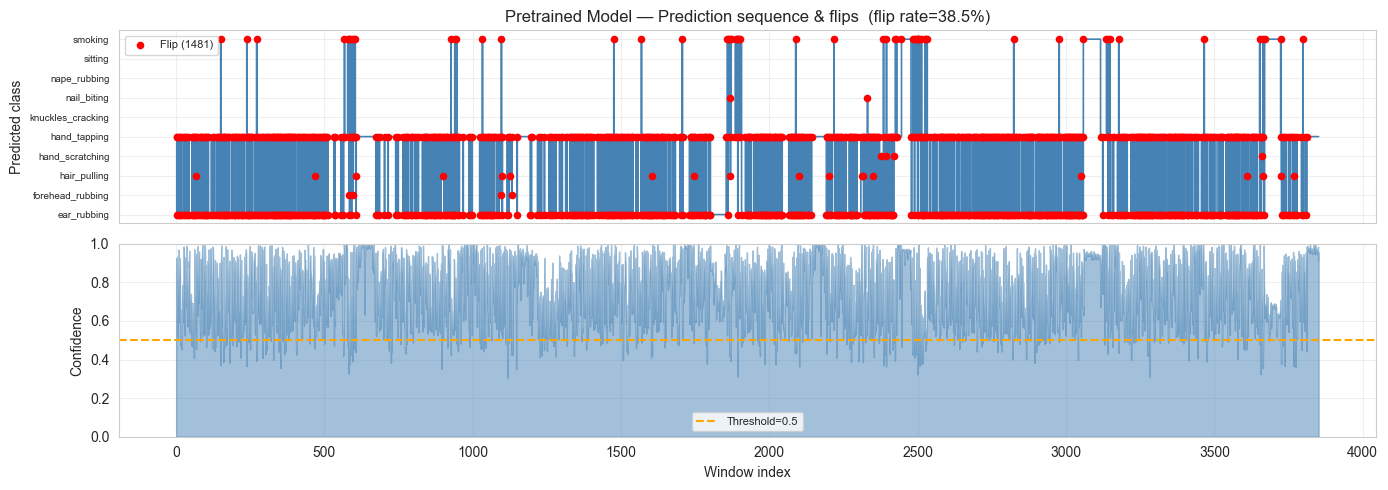

In [126]:
# ===== STEP 6b: FLIP RATE ANALYSIS =====
#
# Flip rate = how often the predicted class changes between consecutive windows.
# Consecutive windows share 50% of their samples (overlap=0.5), so the signal
# barely changes. A stable model should predict the same class for many windows
# in a row. Frequent flipping indicates the model is uncertain or the activity
# itself is genuinely ambiguous near boundaries.
#
# Metrics:
#   flip_rate         → fraction of consecutive window pairs where prediction changed
#   mean_run_length   → average number of windows in a row with the same prediction
#                       (longer = more stable)
#   flip_after_low_conf → do flips happen more often after a low-confidence window?
#                         yes → model flips when it's uncertain (expected, normal)
#                         no  → model flips even when confident (bad sign)

def compute_flip_rate(results, model_name, conf_threshold=0.5):
    acts = results['pred_activities']   # (n_windows,)
    confs = results['confidences']

    if len(acts) < 2:
        print(f'{model_name}: not enough windows for flip analysis')
        return

    # --- flip rate ---
    flips      = acts[1:] != acts[:-1]          # True where class changes
    flip_rate  = flips.mean()

    # --- run length (consecutive same-class windows) ---
    run_lengths = []
    run = 1
    for f in flips:
        if f:
            run_lengths.append(run)
            run = 1
        else:
            run += 1
    run_lengths.append(run)
    mean_run = np.mean(run_lengths)
    max_run  = np.max(run_lengths)

    # --- flip after low-conf ---
    low_conf_before_flip = flips & (confs[:-1] < conf_threshold)
    flip_after_low  = low_conf_before_flip.sum()
    flip_after_high = (flips & (confs[:-1] >= conf_threshold)).sum()
    total_flips = flips.sum()

    print(f'\n{"="*60}')
    print(f'  {model_name} — Flip Rate Analysis')
    print(f'{"="*60}')
    print(f'  Total windows          : {len(acts)}')
    print(f'  Consecutive pairs      : {len(flips)}')
    print(f'  Flip rate              : {flip_rate:.2%}  ({total_flips} flips)')
    print(f'  Mean run length        : {mean_run:.1f} windows  (stable streak)')
    print(f'  Max run length         : {max_run} windows')
    print(f'  Flips after low-conf   : {flip_after_low} / {total_flips}  ({flip_after_low/max(total_flips,1):.0%})')
    print(f'  Flips after high-conf  : {flip_after_high} / {total_flips}  ({flip_after_high/max(total_flips,1):.0%})')

    if flip_rate < 0.05:
        verdict = "Very stable — model is consistent across overlapping windows."
    elif flip_rate < 0.20:
        verdict = "Moderately stable — some transitions, likely near activity boundaries."
    elif flip_rate < 0.50:
        verdict = "Unstable — frequent class changes, model may be uncertain."
    else:
        verdict = "Highly unstable — model is flipping on nearly every window."
    print(f'\n  Verdict: {verdict}')

    # --- plot: flip map ---
    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)

    # Top: prediction sequence
    act_codes = np.array([ACTIVITY_MAPPING.get(a, -1) for a in acts])
    axes[0].step(range(len(act_codes)), act_codes, where='post', linewidth=1.2, color='steelblue')
    axes[0].set_yticks(list(ACTIVITY_MAPPING.values()))
    axes[0].set_yticklabels(list(ACTIVITY_MAPPING.keys()), fontsize=7)
    axes[0].set_ylabel('Predicted class')
    axes[0].set_title(f'{model_name} — Prediction sequence & flips  (flip rate={flip_rate:.1%})')
    axes[0].grid(alpha=0.3)

    # Mark flips as red dots on the top plot
    flip_positions = np.where(flips)[0] + 1
    axes[0].scatter(flip_positions, act_codes[flip_positions],
                    color='red', s=20, zorder=5, label=f'Flip ({total_flips})')
    axes[0].legend(fontsize=8)

    # Bottom: confidence with low-conf threshold line
    axes[1].fill_between(range(len(confs)), confs, alpha=0.5, color='steelblue')
    axes[1].axhline(conf_threshold, color='orange', linestyle='--', linewidth=1.5,
                    label=f'Threshold={conf_threshold}')
    axes[1].set_ylim(0, 1)
    axes[1].set_ylabel('Confidence')
    axes[1].set_xlabel('Window index')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

if results_pretrained:
    compute_flip_rate(results_pretrained, 'Pretrained Model', conf_threshold=CONFIDENCE_THRESHOLD)

if results_trained:
    compute_flip_rate(results_trained, 'Trained Model', conf_threshold=CONFIDENCE_THRESHOLD)

In [127]:
# ===== STEP 7: SAMPLE PREDICTIONS (Top-5 per window) =====

def show_top5_predictions(results, model_name, n_samples=5):
    """
    Display top-5 predicted activities for a sample of windows.
    """
    print(f'\n{model_name} - Top-5 Predictions (sample of {n_samples} windows):')
    print('=' * 80)
    
    for window_idx in range(min(n_samples, len(results['pred_activities']))):
        print(f'\nWindow {window_idx}:')
        print(f'  Predicted (main): {results["pred_activities"][window_idx]} (confidence: {results["confidences"][window_idx]:.4f})')
        print(f'  Top-5:')
        for rank, (activity, prob) in enumerate(zip(
            results['top5_names'][window_idx],
            results['top5_probs'][window_idx]
        ), 1):
            print(f'    {rank}. {activity}: {prob:.4f}')

if results_pretrained:
    show_top5_predictions(results_pretrained, 'PRETRAINED MODEL')

if results_trained:
    show_top5_predictions(results_trained, 'TRAINED MODEL')


PRETRAINED MODEL - Top-5 Predictions (sample of 5 windows):

Window 0:
  Predicted (main): ear_rubbing (confidence: 0.8343)
  Top-5:
    1. ear_rubbing: 0.8343
    2. hair_pulling: 0.0917
    3. smoking: 0.0670
    4. hand_tapping: 0.0048
    5. nail_biting: 0.0009

Window 1:
  Predicted (main): ear_rubbing (confidence: 0.9260)
  Top-5:
    1. ear_rubbing: 0.9260
    2. hand_tapping: 0.0586
    3. hair_pulling: 0.0078
    4. nail_biting: 0.0040
    5. smoking: 0.0034

Window 2:
  Predicted (main): hand_tapping (confidence: 0.8388)
  Top-5:
    1. hand_tapping: 0.8388
    2. ear_rubbing: 0.1553
    3. smoking: 0.0021
    4. hair_pulling: 0.0020
    5. sitting: 0.0007

Window 3:
  Predicted (main): ear_rubbing (confidence: 0.7653)
  Top-5:
    1. ear_rubbing: 0.7653
    2. hand_tapping: 0.2032
    3. smoking: 0.0250
    4. hair_pulling: 0.0041
    5. nail_biting: 0.0019

Window 4:
  Predicted (main): hand_tapping (confidence: 0.5148)
  Top-5:
    1. hand_tapping: 0.5148
    2. ear_rubbi

## Evaluation Metrics
Computes accuracy, macro metrics, and confusion matrix values when labels are available.


In [128]:
# ===== STEP 8: EVALUATION METRICS (if labels available) =====

def compute_metrics(y_true, y_pred_activities, y_confidences, model_name, activity_mapping):
    """
    Compute accuracy, precision, recall, F1 (macro and per-class).
    Returns dict with all metrics.
    """
    # Convert activity names to indices for sklearn. y_true may already be
    # production-style integer labels from create_windows().
    y_pred_idx = np.array([activity_mapping.get(act, -1) for act in y_pred_activities])
    y_true_arr = np.asarray(y_true)
    if np.issubdtype(y_true_arr.dtype, np.integer):
        y_true_idx = y_true_arr.astype(np.int32)
    else:
        y_true_idx = np.array([activity_mapping.get(act, -1) for act in y_true_arr])

    if len(y_true_idx) != len(y_pred_idx):
        raise ValueError(
            f'Refusing to compute accuracy with mismatched arrays: '
            f'len(y_true)={len(y_true_idx)} len(y_pred)={len(y_pred_idx)}. '
            'Rebuild a paired X/y set; do not use stale production_y.npy.'
        )
    
    # Filter out unmapped classes
    valid = (y_pred_idx != -1) & (y_true_idx != -1)
    y_true_idx = y_true_idx[valid]
    y_pred_idx = y_pred_idx[valid]
    y_confidences = y_confidences[valid]
    
    accuracy = accuracy_score(y_true_idx, y_pred_idx)
    precision_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    recall_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    
    # Per-class metrics
    report = classification_report(y_true_idx, y_pred_idx, output_dict=True, zero_division=0)
    
    # Confusion matrix
    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=list(activity_mapping.values()))
    
    return {
        'model': model_name,
        'accuracy': accuracy,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro,
        'confidence_mean': y_confidences.mean(),
        'confidence_std': y_confidences.std(),
        'per_class_report': report,
        'confusion_matrix': cm,
        'y_true': y_true_idx,
        'y_pred': y_pred_idx,
        'confidences': y_confidences
    }

metrics_pretrained = None
metrics_trained = None

if y is not None:
    print('\n=== EVALUATION METRICS ===')
    
    if results_pretrained:
        print('\nPRETRAINED MODEL:')
        metrics_pretrained = compute_metrics(y, results_pretrained['pred_activities'],
                                              results_pretrained['confidences'],
                                              'Pretrained', ACTIVITY_MAPPING)
        print(f"  Accuracy: {metrics_pretrained['accuracy']:.4f}")
        print(f"  Precision (macro): {metrics_pretrained['precision_macro']:.4f}")
        print(f"  Recall (macro): {metrics_pretrained['recall_macro']:.4f}")
        print(f"  F1 (macro): {metrics_pretrained['f1_macro']:.4f}")
        print(f"  Confidence mean: {metrics_pretrained['confidence_mean']:.4f}")
        print(f"  Confidence std: {metrics_pretrained['confidence_std']:.4f}")
    
    if results_trained:
        print('\nTRAINED MODEL:')
        metrics_trained = compute_metrics(y, results_trained['pred_activities'],
                                           results_trained['confidences'],
                                           'Trained', ACTIVITY_MAPPING)
        print(f"  Accuracy: {metrics_trained['accuracy']:.4f}")
        print(f"  Precision (macro): {metrics_trained['precision_macro']:.4f}")
        print(f"  Recall (macro): {metrics_trained['recall_macro']:.4f}")
        print(f"  F1 (macro): {metrics_trained['f1_macro']:.4f}")
        print(f"  Confidence mean: {metrics_trained['confidence_mean']:.4f}")
        print(f"  Confidence std: {metrics_trained['confidence_std']:.4f}")
else:
    print('\nNo labels available - skipping evaluation metrics')


=== EVALUATION METRICS ===

PRETRAINED MODEL:
  Accuracy: 0.1057
  Precision (macro): 0.0223
  Recall (macro): 0.1089
  F1 (macro): 0.0358
  Confidence mean: 0.7666
  Confidence std: 0.1685


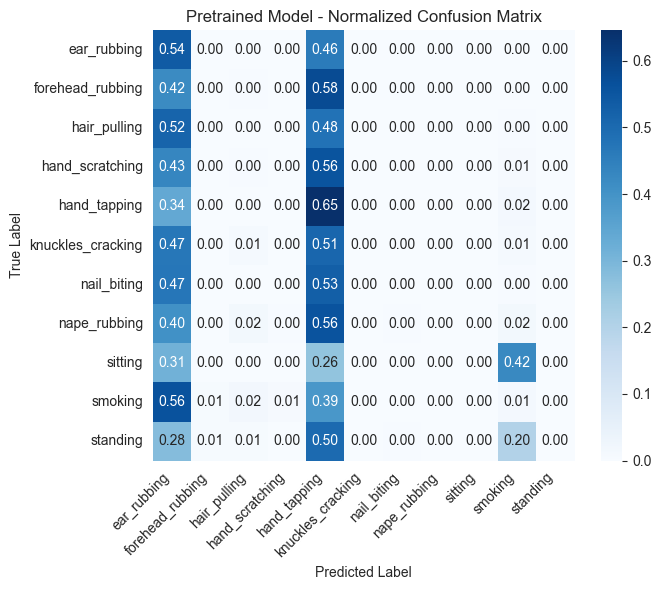

In [129]:
# ===== STEP 9: CONFUSION MATRICES =====

available = []
if metrics_pretrained:
    available.append((metrics_pretrained, 'Pretrained'))
if metrics_trained:
    available.append((metrics_trained, 'Trained'))

if available:
    fig, axes = plt.subplots(1, len(available), figsize=(7 * len(available), 6), squeeze=False)
    axes = axes.flatten()

    for ax, (metrics, name) in zip(axes, available):
        cm = metrics['confusion_matrix']
        cm_normalized = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-8)

        sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=list(ACTIVITY_MAPPING.keys()),
                    yticklabels=list(ACTIVITY_MAPPING.keys()),
                    cbar=True, ax=ax)
        ax.set_title(f'{name} Model - Normalized Confusion Matrix')
        ax.set_ylabel('True Label')
        ax.set_xlabel('Predicted Label')
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.show()
else:
    print('No metrics available for confusion matrices')


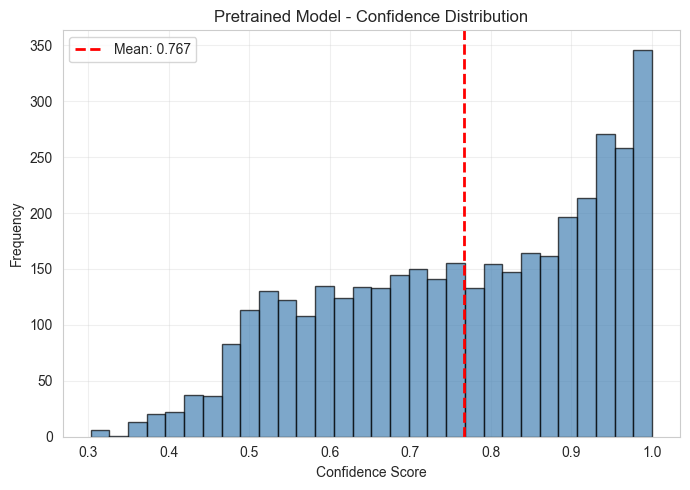

In [130]:
# ===== STEP 10: CONFIDENCE DISTRIBUTIONS =====

available = []
if results_pretrained:
    available.append((results_pretrained, 'Pretrained'))
if results_trained:
    available.append((results_trained, 'Trained'))

if available:
    fig, axes = plt.subplots(1, len(available), figsize=(7 * len(available), 5), squeeze=False)
    axes = axes.flatten()

    for ax, (results, name) in zip(axes, available):
        ax.hist(results['confidences'], bins=30, alpha=0.7, edgecolor='black', color='steelblue')
        ax.axvline(results['confidences'].mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {results["confidences"].mean():.3f}')
        ax.set_title(f'{name} Model - Confidence Distribution')
        ax.set_xlabel('Confidence Score')
        ax.set_ylabel('Frequency')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print('No results available for confidence distributions')


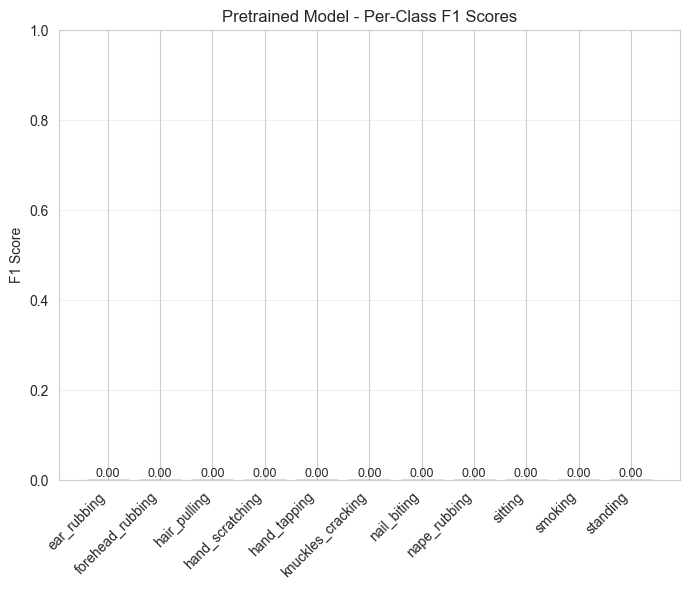

In [131]:
# ===== STEP 11: PER-CLASS F1 SCORES =====

available = []
if metrics_pretrained:
    available.append((metrics_pretrained, 'Pretrained'))
if metrics_trained:
    available.append((metrics_trained, 'Trained'))

if available:
    fig, axes = plt.subplots(1, len(available), figsize=(7 * len(available), 6), squeeze=False)
    axes = axes.flatten()

    for ax, (metrics, name) in zip(axes, available):
        report = metrics['per_class_report']
        activities = list(ACTIVITY_MAPPING.keys())
        f1_scores = [report.get(act, {}).get('f1-score', 0) for act in activities]

        colors = ['#1f77b4' if f > 0 else '#d62728' for f in f1_scores]
        bars = ax.bar(activities, f1_scores, color=colors, alpha=0.7, edgecolor='black')
        ax.set_title(f'{name} Model - Per-Class F1 Scores')
        ax.set_ylabel('F1 Score')
        ax.set_ylim([0, 1])
        ax.grid(axis='y', alpha=0.3)
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

        for bar, score in zip(bars, f1_scores):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{score:.2f}', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print('No metrics available for per-class F1 scores')


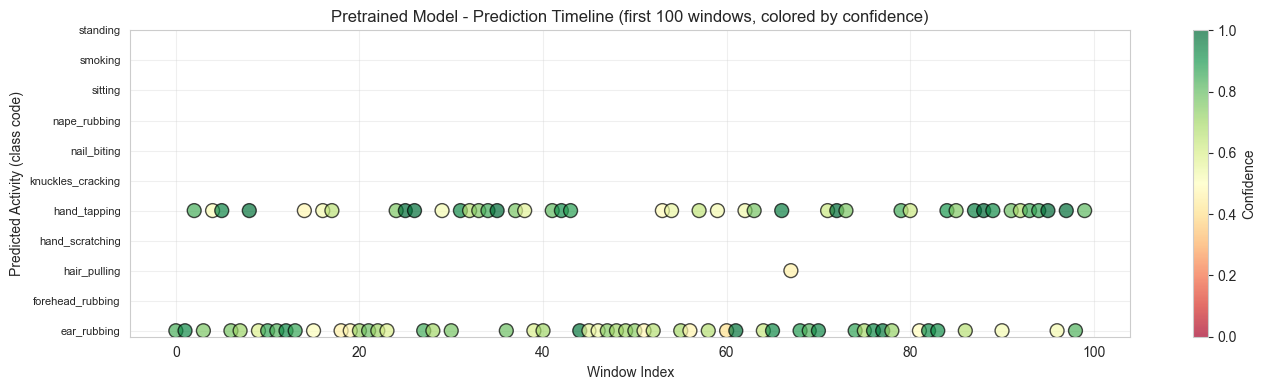

In [132]:
# ===== STEP 12: PREDICTION TIMELINE (temporal sequence of predictions) =====

available = []
if results_pretrained:
    available.append((results_pretrained, 'Pretrained'))
if results_trained:
    available.append((results_trained, 'Trained'))

if available:
    activity_to_code = ACTIVITY_MAPPING

    fig, axes = plt.subplots(len(available), 1, figsize=(14, 4 * len(available)), squeeze=False)
    axes = axes.flatten()

    for ax, (results, name) in zip(axes, available):
        # Limit timeline to first 100 windows for readability
        window_range = min(100, len(results['pred_activities']))
        pred_codes = np.array([activity_to_code.get(act, -1) for act in results['pred_activities'][:window_range]])
        confidences = results['confidences'][:window_range]

        scatter = ax.scatter(range(window_range), pred_codes, c=confidences, cmap='RdYlGn',
                             s=100, alpha=0.7, edgecolor='black', vmin=0, vmax=1)
        ax.set_title(f'{name} Model - Prediction Timeline (first {window_range} windows, colored by confidence)')
        ax.set_ylabel('Predicted Activity (class code)')
        ax.set_xlabel('Window Index')
        ax.set_yticks(list(activity_to_code.values()))
        ax.set_yticklabels(list(activity_to_code.keys()), fontsize=8)
        ax.grid(alpha=0.3)

        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label('Confidence')

    plt.tight_layout()
    plt.show()
else:
    print('No results available for prediction timeline')


## Data Drift Analysis
Compares the current recording against training reference data using PSI, JSD, Z-mean, and Wasserstein distance.


In [133]:
# ===== DATA DRIFT ANALYSIS =====

if not APPLY_CANONICAL_SCALER:
    print('Skipping drift analysis: APPLY_CANONICAL_SCALER=False means X is raw/debug-space, while DriftMonitor expects canonical scaled windows.')
    drift_results = {}
else:
    # Uses src/monitoring/drift_monitor.py:DriftMonitor as the production-grade
    # pass/fail signal:
    #   - PSI per channel (threshold 0.15)
    #   - Post-z mean check (|mean| > 0.3)
    #   - Post-z std check (std > 1.3)
    # Reference is models/drift_reference.json. If missing, we calibrate from
    # data/all_users_data_labeled.csv (users 1-4 windows) and save it.
    #
    # KDE / JSD (shared bins) / Wasserstein remain as supplementary diagnostics.

    import json as _json
    import matplotlib.gridspec as gridspec
    from scipy.stats import wasserstein_distance
    from scipy.spatial.distance import jensenshannon

    REF_DATA_PATH    = Path(DRIFT_REFERENCE_DATA)
    REF_MONITOR_PATH = Path(DRIFT_REFERENCE_PATH)

    # ---------------------------------------------------------------- DriftMonitor
    def _calibrate_reference_from_csv(csv_path: Path, monitor: DriftMonitor) -> dict:
        """Calibrate DriftMonitor reference using train users (1-4) from a labeled CSV.

        Applies the canonical scaler to raw rows so that PSI bin edges match the
        z-scored space the monitor expects.
        """
        print(f'  Calibrating drift reference from: {csv_path}')
        if not csv_path.exists():
            raise FileNotFoundError(f'Reference data not found: {csv_path}')
        ref = pd.read_csv(csv_path)

        # Map columns to canonical order; rename _w variants to match the scaler.
        rename = _build_alias_rename_map(ref.columns.tolist(), SENSOR_COLUMN_ALIASES)
        if rename:
            ref = ref.rename(columns=rename)
        canonical_cols = ['Ax', 'Ay', 'Az', 'Gx', 'Gy', 'Gz']
        missing = [c for c in canonical_cols if c not in ref.columns]
        if missing:
            raise ValueError(f'Reference CSV missing canonical sensor cols: {missing}')

        if 'User' not in ref.columns:
            raise ValueError('Reference CSV missing "User" column needed for users 1-4 split.')

        train_mask = ref['User'].isin([1, 2, 3, 4])
        rows = ref.loc[train_mask, canonical_cols].to_numpy(dtype=np.float32)
        users = ref.loc[train_mask, 'User'].to_numpy(dtype=np.int32)

        # Apply canonical scaler
        mean, scale, _ = load_canonical_scaler()
        safe_scale = np.where(scale == 0, 1.0, scale)
        rows = (rows - mean) / safe_scale

        # Window per user with the production sizes
        Xw = []
        for u in sorted(np.unique(users)):
            idx = np.where(users == u)[0]
            x_u = rows[idx]
            for start in range(0, len(x_u) - WINDOW_SIZE + 1, WINDOW_STEP):
                Xw.append(x_u[start:start + WINDOW_SIZE])
        if not Xw:
            raise RuntimeError('No reference windows produced (insufficient train-user data).')
        Xw = np.asarray(Xw, dtype=np.float32)
        print(f'  Reference windows shape: {Xw.shape}')
        return monitor.calibrate(Xw, save=True)


    print('=== DriftMonitor (production gate) ===')
    drift_monitor = DriftMonitor(reference_path=REF_MONITOR_PATH)
    if drift_monitor.reference is None:
        print(f'  Reference missing at {REF_MONITOR_PATH}; calibrating...')
        _calibrate_reference_from_csv(REF_DATA_PATH, drift_monitor)
        drift_monitor = DriftMonitor(reference_path=REF_MONITOR_PATH)  # reload
    else:
        print(f'  Loaded existing reference: {REF_MONITOR_PATH}')

    # Run the production check on current windows (X is float32 (N,200,6) from Step 4).
    probabilities = (results_pretrained['probs'] if results_pretrained is not None
                     else (results_trained['probs'] if results_trained is not None else None))
    drift_report = drift_monitor.check(X, probabilities=probabilities)

    print(f'\n--- DriftMonitor result ---')
    print(f'  Windows checked       : {drift_report["n_windows_checked"]}')
    print(f'  Max PSI (threshold {drift_monitor.psi_threshold:.2f}) : {drift_report["max_psi"]:.4f}')
    print(f'  Drift detected        : {drift_report["drift_detected"]}')
    print(f'  Recommended action    : {drift_report["action_recommended"]}')
    print(f'\n  Per-channel PSI:')
    for ch, val in drift_report['psi_per_channel'].items():
        flag = ' DRIFT' if val > drift_monitor.psi_threshold else ''
        print(f'    {ch}: {val:.4f}{flag}')
    print(f'\n  Post-z mean / std (alert if |mean|>{drift_monitor.post_z_mean_threshold} or std>{drift_monitor.post_z_std_threshold}):')
    for ch in DRIFT_CHANNELS:
        mu = drift_report['post_z_mean_per_channel'][ch]
        sd = drift_report['post_z_std_per_channel'][ch]
        flag = ' ALERT' if drift_report['post_z_alert_per_channel'][ch] else ''
        print(f'    {ch}: mean={mu:+.3f}  std={sd:.3f}{flag}')
    if not np.isnan(drift_report['entropy_mean']):
        print(f'\n  Entropy mean: {drift_report["entropy_mean"]:.4f}  '
              f'(p95 threshold: {drift_report["entropy_threshold_p95"]})')

    # ---------------------------------------------------- Supplementary diagnostics
    print('\n=== Supplementary distribution diagnostics (KDE / JSD / Wasserstein) ===')

    # Use the canonical reference CSV (train users only) as the supplementary reference.
    ref_df = pd.read_csv(REF_DATA_PATH)
    _supp_rename = _build_alias_rename_map(ref_df.columns.tolist(), SENSOR_COLUMN_ALIASES)
    if _supp_rename:
        ref_df = ref_df.rename(columns=_supp_rename)
    if 'User' in ref_df.columns:
        ref_df = ref_df[ref_df['User'].isin([1, 2, 3, 4])].reset_index(drop=True)
    print(f'  Reference rows (users 1-4): {len(ref_df)}')

    cur_cols = list(accel_cols) + list(gyro_cols)  # already canonical
    ref_cols = ['Ax', 'Ay', 'Az', 'Gx', 'Gy', 'Gz']
    axis_pairs = list(zip(ref_cols, cur_cols))


    def compute_psi(expected, actual, n_bins=20):
        mn = min(expected.min(), actual.min())
        mx = max(expected.max(), actual.max())
        bins = np.linspace(mn, mx, n_bins + 1)
        exp_hist, _ = np.histogram(expected, bins=bins)
        act_hist, _ = np.histogram(actual,   bins=bins)
        eps = 1e-8
        exp_pct = (exp_hist + eps) / (exp_hist.sum() + eps)
        act_pct = (act_hist + eps) / (act_hist.sum() + eps)
        return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct))), bins, exp_pct, act_pct


    def psi_label(p):
        if p < 0.10: return 'NO DRIFT', 'green'
        if p < 0.20: return 'MODERATE DRIFT', 'orange'
        return 'SIGNIFICANT', 'red'


    def jsd_label(j):
        if j < 0.10: return 'LOW', 'green'
        if j < 0.25: return 'MODERATE', 'orange'
        return 'HIGH', 'red'


    # Apply canonical scaler to reference rows so supplementary plots are in the same
    # z-scored space as df_processed (which is already scaled).
    _mean, _scale, _ = load_canonical_scaler()
    _safe_scale = np.where(_scale == 0, 1.0, _scale)

    drift_results = {}
    RNG = np.random.default_rng(42)

    for i, (ref_col, cur_col) in enumerate(axis_pairs):
        ref_vals_raw = ref_df[ref_col].dropna().values.astype(np.float32)
        ref_vals = (ref_vals_raw - _mean[i]) / _safe_scale[i]
        cur_vals = df_processed[cur_col].dropna().values.astype(np.float32)
        if len(ref_vals) > 60_000:
            ref_vals = RNG.choice(ref_vals, 60_000, replace=False)

        psi_val, bins, exp_pct, act_pct = compute_psi(ref_vals, cur_vals)
        jsd_lo = float(min(ref_vals.min(), cur_vals.min()))
        jsd_hi = float(max(ref_vals.max(), cur_vals.max()))
        shared_bins = np.linspace(jsd_lo, jsd_hi, 51)
        jsd_val = float(jensenshannon(
            np.histogram(ref_vals, bins=shared_bins, density=True)[0] + 1e-8,
            np.histogram(cur_vals, bins=shared_bins, density=True)[0] + 1e-8))
        wass_val = float(wasserstein_distance(ref_vals, cur_vals))
        zmean = abs(cur_vals.mean() - 0.0)  # z-scored space => target mean 0
        zstd  = cur_vals.std()

        psi_lbl, psi_clr = psi_label(psi_val)
        jsd_lbl, jsd_clr = jsd_label(jsd_val)
        z_lbl   = 'OK' if zmean < 0.3 else ('WATCH' if zmean < 0.5 else 'FLAG')
        z_clr   = 'green' if zmean < 0.3 else ('orange' if zmean < 0.5 else 'red')

        drift_results[ref_col] = dict(
            ref_col=ref_col, cur_col=cur_col,
            ref_mean=float(ref_vals.mean()), cur_mean=float(cur_vals.mean()),
            ref_std=float(ref_vals.std()),   cur_std=float(cur_vals.std()),
            psi=psi_val, psi_lbl=psi_lbl, psi_clr=psi_clr,
            jsd=jsd_val, jsd_lbl=jsd_lbl, jsd_clr=jsd_clr,
            wass=wass_val,
            zmean=zmean, zstd=zstd, z_lbl=z_lbl, z_clr=z_clr,
            ref_vals=ref_vals, cur_vals=cur_vals,
            bins=bins, exp_pct=exp_pct, act_pct=act_pct,
        )

    print(f'\n{"="*90}')
    print(f'{"Axis":<8} {"PSI":>8} {"PSI Status":<18} {"JSD":>6} {"JSD Status":<14} {"|z-mean|":>9} {"z-std":>7} {"Wass.":>8}')
    print(f'{"-"*90}')
    for col, r in drift_results.items():
        print(f'{col:<8} {r["psi"]:>8.4f} {r["psi_lbl"]:<18} '
              f'{r["jsd"]:>6.4f} {r["jsd_lbl"]:<14} '
              f'{r["zmean"]:>9.3f} {r["zstd"]:>7.3f} {r["wass"]:>8.3f}')

    overall_psi  = float(np.mean([r['psi']  for r in drift_results.values()]))
    overall_jsd  = float(np.mean([r['jsd']  for r in drift_results.values()]))
    print(f'{"-"*90}')
    print(f'{"OVERALL":<8} {overall_psi:>8.4f} {psi_label(overall_psi)[0]:<18} '
          f'{overall_jsd:>6.4f} {jsd_label(overall_jsd)[0]:<14}')

    # ---------- Plot 1: KDE overlay 2x3 grid ----------
    fig = plt.figure(figsize=(17, 10))
    fig.suptitle('Data Drift - Training (z-scored) vs Current  (KDE per axis)',
                 fontsize=13, fontweight='bold')
    gs = gridspec.GridSpec(2, 3, hspace=0.45, wspace=0.35)

    for idx, (ref_col, _) in enumerate(axis_pairs):
        r  = drift_results[ref_col]
        ax = fig.add_subplot(gs[idx // 3, idx % 3])
        for vals, lbl, clr, alp in [
            (r['ref_vals'], 'Reference (train, z-scored)', '#2196F3', 0.45),
            (r['cur_vals'], 'Current (z-scored)',          '#FF5722', 0.45),
        ]:
            counts, bins_ = np.histogram(vals, bins=80, density=True)
            bc = (bins_[:-1] + bins_[1:]) / 2
            ax.fill_between(bc, counts, alpha=alp, color=clr, label=lbl)
            ax.plot(bc, counts, color=clr, lw=1.1)
        ax.set_title(f'{ref_col}  |  PSI={r["psi"]:.3f} ({r["psi_lbl"]})',
                     color=r['psi_clr'], fontweight='bold', fontsize=9)
        ax.set_xlabel('Value', fontsize=8); ax.set_ylabel('Density', fontsize=8)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.show()

    # ---------- Plot 2: Bar charts ----------
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    fig.suptitle('Drift Metrics per Axis (supplementary)', fontsize=12, fontweight='bold')

    for ax, (metric, thresh_lo, thresh_hi, ylabel, title) in zip(axes, [
        ('psi',  0.10, 0.20, 'PSI',  'PSI  (supplementary - production threshold 0.15)'),
        ('jsd',  0.10, 0.25, 'JSD',  'Jensen-Shannon Divergence  [0-1]'),
        ('zmean',0.3,  0.5,  '|z-mean|',  '|z-mean| in scaled space  (production threshold 0.3)'),
    ]):
        vals = [drift_results[k][metric] for k in ref_cols]
        colors = [drift_results[k]['psi_clr' if metric=='psi' else
                                   'jsd_clr' if metric=='jsd' else 'z_clr']
                  for k in ref_cols]
        bars = ax.bar(ref_cols, vals, color=colors, alpha=0.8, edgecolor='black')
        ax.axhline(thresh_lo, color='orange', linestyle='--', lw=1.5,
                   label=f'Watch >{thresh_lo}')
        ax.axhline(thresh_hi, color='red',    linestyle='--', lw=1.5,
                   label=f'Significant >{thresh_hi}')
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8)
        ax.set_title(title, fontsize=9); ax.set_ylabel(ylabel)
        ax.legend(fontsize=7); ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

    print('\nThresholds:')
    print('  PSI  : production gate at 0.15 (DriftMonitor); supplementary >0.20 = significant')
    print('  JSD  : <0.10 low / 0.10-0.25 moderate / >0.25 high')
    print('  |z|  : production post-z mean threshold = 0.3; std threshold = 1.3')


Skipping drift analysis: APPLY_CANONICAL_SCALER=False means X is raw/debug-space, while DriftMonitor expects canonical scaled windows.


## Final Summary
Prints the key preprocessing, model, evaluation, and drift results in one place.


In [134]:
# ===== FINAL SUMMARY REPORT =====

print('\n' + '='*80)
print('FINAL SUMMARY REPORT')
print('='*80)

print(f'\n[Data]')
print(f'  Raw shape          : {df_raw.shape}')
print(f'  Processed shape    : {df_processed.shape}')
print(f'  Windows generated  : {X.shape[0]}')
print(f'  Window size        : {WINDOW_SIZE} samples  |  Overlap: {WINDOW_OVERLAP*100:.0f}%')

print(f'\n[Preprocessing]')
print(f'  Unit conversion    : {UNIT_CONVERSION}')
print(f'  Gravity removal    : {GRAVITY_REMOVAL}')
print(f'  Canonical scaler   : {globals().get("ZSCORE_NORMALIZATION", globals().get("APPLY_CANONICAL_SCALER", None))}')
print(f'  Accel cols         : {accel_cols}')
print(f'  Gyro  cols         : {gyro_cols}')
print(f'  Labels             : {label_col}  (has_labels={y is not None})')

for res, name in [(results_pretrained,'PRETRAINED'), (results_trained,'TRAINED')]:
    if res is None:
        continue
    c, ent, mar = res['confidences'], res['entropy'], res['margin']
    low = (c < CONFIDENCE_THRESHOLD).mean()
    print(f'\n[{name} MODEL — Confidence]')
    print(f'  Mean±std           : {c.mean():.4f} ± {c.std():.4f}')
    print(f'  Min / Max          : {c.min():.4f} / {c.max():.4f}')
    print(f'  Low-conf rate      : {low:.2%}  (threshold={CONFIDENCE_THRESHOLD})')
    print(f'  Entropy mean       : {ent.mean():.4f}  |  Margin mean: {mar.mean():.4f}')
    print(f'  Ambiguous windows  : {(mar < 0.10).mean():.2%}')

for mets, name in [(metrics_pretrained,'PRETRAINED'), (metrics_trained,'TRAINED')]:
    if mets is None:
        continue
    print(f'\n[{name} MODEL — Evaluation]')
    print(f'  Accuracy           : {mets["accuracy"]:.4f}')
    print(f'  Precision (macro)  : {mets["precision_macro"]:.4f}')
    print(f'  Recall (macro)     : {mets["recall_macro"]:.4f}')
    print(f'  F1 (macro)         : {mets["f1_macro"]:.4f}')

if metrics_pretrained and metrics_trained:
    print(f'\n[MODEL COMPARISON]')
    print(f'  Accuracy Δ         : {metrics_trained["accuracy"]  - metrics_pretrained["accuracy"]:+.4f}')
    print(f'  F1 Δ               : {metrics_trained["f1_macro"]  - metrics_pretrained["f1_macro"]:+.4f}')

if drift_results:
    print(f'\n[DATA DRIFT SUMMARY]')
    print(f'  {"Axis":<12} {"PSI":>8}  {"PSI Status":<18} {"JSD":>6}  {"Z-mean":>7}  {"Z Status"}')
    print(f'  {"-"*65}')
    for col, r in drift_results.items():
        print(f'  {col:<12} {r["psi"]:>8.4f}  {r["psi_lbl"]:<18} {r["jsd"]:>6.4f}  {r["zmean"]:>7.3f}  {r["z_lbl"]}')
    overall_psi = np.mean([r['psi'] for r in drift_results.values()])
    overall_jsd = np.mean([r['jsd'] for r in drift_results.values()])
    overall_z   = np.mean([r['zmean'] for r in drift_results.values()])
    p_lbl = psi_label(overall_psi)[0]
    j_lbl = jsd_label(overall_jsd)[0]
    z_lbl = 'OK' if overall_z < 1 else ('WATCH' if overall_z < 2 else 'FLAG')
    print(f'  {"-"*65}')
    print(f'  {"OVERALL":<12} {overall_psi:>8.4f}  {p_lbl:<18} {overall_jsd:>6.4f}  {overall_z:>7.3f}  {z_lbl}')

print(f'\n' + '='*80)


FINAL SUMMARY REPORT

[Data]
  Raw shape          : (385326, 9)
  Processed shape    : (385326, 9)
  Windows generated  : 3852
  Window size        : 200 samples  |  Overlap: 50%

[Preprocessing]
  Unit conversion    : False
  Gravity removal    : False
  Canonical scaler   : False
  Accel cols         : ['Ax', 'Ay', 'Az']
  Gyro  cols         : ['Gx', 'Gy', 'Gz']
  Labels             : activity  (has_labels=True)

[PRETRAINED MODEL — Confidence]
  Mean±std           : 0.7666 ± 0.1685
  Min / Max          : 0.3033 / 1.0000
  Low-conf rate      : 7.17%  (threshold=0.5)
  Entropy mean       : 0.6211  |  Margin mean: 0.5911
  Ambiguous windows  : 7.11%

[PRETRAINED MODEL — Evaluation]
  Accuracy           : 0.1057
  Precision (macro)  : 0.0223
  Recall (macro)     : 0.1089
  F1 (macro)         : 0.0358

